# Week 8 · Your First Model
**The Evolution of Machine Learning and AI · SETU**

This notebook trains a **model that learns your law with no data**: it guesses, checks the guess against your law at many *checking points*, works out the blame, and nudges itself, thousands of times. Then it tests the model against your **answer sheet** from Week 7, and runs your **success test**.

### How to use this notebook (read this first)
- Run the cells **in order, from top to bottom** (click inside a cell and press **Shift + Enter**).
- You only type in cells marked ✏️ **YOUR TURN**. Everything else, you just run.
- Training takes **a few seconds to about a minute** per model. Part 4 takes about a minute.
- If something goes wrong, click **Runtime → Restart session**, then run the cells again from the top.

| Part | What it does | Who runs it |
|---|---|---|
| Step 0 | Loads the tools | everyone |
| Part A | The speed visualiser (this week's topic) | everyone |
| Part 1 | The class example: a model learns the sourdough starter | everyone (just run it) |
| Part 2 | **Your first model**, if one thing changes over time | most of you |
| Part 3 | **Your first model**, if two or three things change each other | only if this is your law's shape |
| Part 4 | **Your first model**, if it changes over time and along a line | only if this is your law's shape |

Use the same part as in Week 7. Your personal roadmap on Moodle says which.

## Step 0 · Load the tools (run once)
This cell loads the training tools. You do not need to read or change it: just run it, and wait for *Ready*.

In [1]:
# ---------- Step 0 tools: run this cell once. You do not need to read or change it. ----------
import time
import numpy as onp                     # ordinary NumPy, for the answer sheet and the pictures
import jax, jax.numpy as np             # "np" is JAX here, so the model can learn from your law line
from jax import grad, jit, vmap
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)

def _init(sizes, seed=0):
    key = jax.random.PRNGKey(seed); params = []
    for m, n in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        params.append((jax.random.normal(k, (m, n)) * np.sqrt(1.0 / m), np.zeros(n)))
    return params

def _net(params, z):
    for W, b in params[:-1]:
        z = np.tanh(z @ W + b)
    W, b = params[-1]
    return z @ W + b

def _adam(loss, params, steps, lr):
    flat, unravel = jax.flatten_util.ravel_pytree(params)
    g_fn = jit(grad(lambda f, c: loss(unravel(f), c))); l_fn = jit(lambda f: loss(unravel(f), 1.0))
    m = onp.zeros_like(flat); v = onp.zeros_like(flat); hist = []
    for k in range(1, steps + 1):
        rate = lr * (0.05 + 0.95 * 0.5 * (1 + onp.cos(onp.pi * k / steps)))   # smaller steps as it goes
        g = onp.asarray(g_fn(flat, min(1.0, 0.15 + k / (0.6 * steps))))   # learn the early times first
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        flat = flat - rate * (m / (1 - 0.9 ** k)) / (onp.sqrt(v / (1 - 0.999 ** k)) + 1e-8)
        if k % 25 == 0 or k == 1: hist.append((k, float(l_fn(flat))))
    return unravel(flat), hist

import jax.flatten_util

def learn_law(rate, start, t_end, n_points=200, steps=3000, width=32, lr=0.01, seed=0):
    """Train a small network that obeys the law, with no data. Works for one thing or several."""
    start = np.atleast_1d(np.asarray(start, dtype=float)); k = start.shape[0]
    params = _init([1, width, width, k], seed)
    tau = np.linspace(0, 1, n_points)[:, None]                       # checking points, as fractions of t_end
    f = lambda t, y: np.atleast_1d(np.asarray(rate(t, y if k > 1 else y[0]), dtype=float))
    scale = np.maximum(np.abs(f(0.0, start if k > 1 else start)), 1e-6)  # keeps the leftover near 1
    f0 = f(0.0, start)                                                # the law's slope at the start
    size = np.maximum(np.maximum(np.abs(start), np.abs(f0) * t_end), 1e-3)   # the size of the answer
    def u(p, s): return start + s * t_end * f0 + s ** 2 * size * _net(p, s)   # the start and its slope are built in
    def leftover(p, s):
        du = jax.jacfwd(lambda z: u(p, z))(s)[:, 0] / t_end          # how fast the model changes
        return (du - f(s[0] * t_end, u(p, s))) / scale              # ... minus what the law says
    def loss(p, c):                                                    # c: how far along the time range to check
        w = jax.nn.sigmoid((c - tau[:, 0]) * 40.0)
        return np.sum(w[:, None] * vmap(lambda s: leftover(p, s))(tau) ** 2) / (np.sum(w) * k)
    t0 = time.time()
    best = None
    for attempt in range(3):                                          # if training gets stuck, start again
        params, hist = _adam(loss, _init([1, width, width, k], seed + attempt), steps, lr)
        if best is None or hist[-1][1] < best[1][-1][1]: best = (params, hist)
        if hist[-1][1] < 0.05: break
        print(f"  Training got stuck (loss {hist[-1][1]:.2g}); starting again from a different guess...")
    params, hist = best
    secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda t: onp.asarray(vmap(lambda s: u(params, s))(np.asarray(t, dtype=float)[:, None] / t_end))
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points)

def report(result, answer_t, answer_y, names, time_unit, check_time, check_tolerance, which=0, picture="my_first_model.png"):
    """Draw the loss curve and the model against the answer sheet, and run the success test."""
    t = onp.asarray(answer_t); Y = onp.atleast_2d(onp.asarray(answer_y)); M = result["model"](t).T
    err = float(onp.max(onp.abs(M - Y)))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)")
    ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    for i, n in enumerate(names):
        ax[1].plot(t, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n}")
        ax[1].plot(t, M[i], "--", color="#0B4651", linewidth=2, label=f"model: {n}")
    ax[1].axvline(check_time, color="#B3261E", linestyle=":", label="success test time")
    ax[1].set_xlabel(f"time ({time_unit})"); ax[1].set_title("Model against the answer sheet"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    model_at = float(result["model"](onp.array([check_time]))[0][which])
    sheet_at = float(onp.interp(check_time, t, Y[which]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at {check_time:g} {time_unit}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    print(f"Saved as {picture}.")
    return dict(error=err, passed=ok, seconds=result["seconds"], size=result["size"])

def learn_line_law(line_law, u0, L, t_end, ends=None, n_points=3000, steps=3000, width=32, lr=0.005, seed=0):
    """Train a network u(x, t) that obeys a law along a line. line_law(u, u_x, u_xx) gives how fast u changes."""
    params = _init([2, width, width, width, 1], seed)
    key = jax.random.PRNGKey(seed + 1)
    pts = jax.random.uniform(key, (n_points, 2))                     # checking points: (place, time) as fractions
    du0 = grad(lambda xx: u0(xx)); ddu0 = grad(du0)
    rate0 = lambda xx: line_law(u0(xx), du0(xx), ddu0(xx))           # the law's slope at the start, along the line
    size = float(onp.max(onp.abs(onp.asarray(vmap(rate0)(np.linspace(0.0, L, 201)))))) * t_end + 1e-3
    def u(p, xs, ts):          # start and its slope built in; the two ends stay fixed (the factor xs * (1 - xs))
        edge = 4.0 * xs * (1.0 - xs)
        return u0(xs * L) + edge * (ts * t_end * rate0(xs * L) + ts ** 2 * size * _net(p, np.array([xs, ts]))[0])
    def leftover(p, z):
        xs, ts = z[0], z[1]
        u_t = grad(u, 2)(p, xs, ts) / t_end
        u_x = grad(u, 1)(p, xs, ts) / L
        u_xx = grad(grad(u, 1), 1)(p, xs, ts) / L ** 2
        return (u_t - line_law(u(p, xs, ts), u_x, u_xx)) * t_end / (size + 1e-9)
    def loss(p, c):
        w = jax.nn.sigmoid((c - pts[:, 1]) * 40.0)
        return np.sum(w * vmap(lambda z: leftover(p, z))(pts) ** 2) / np.sum(w)
    t0 = time.time(); params, hist = _adam(loss, params, steps, lr); secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda x, t: onp.asarray(vmap(lambda xs: u(params, xs, t / t_end))(np.asarray(x, dtype=float) / L))
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points)

def line_answer_sheet(line_law, u0, L, t_end, times, N=101):
    """The answer sheet for a law along a line, from the standard solver (the two ends stay fixed)."""
    x = onp.linspace(0, L, N); dx = x[1] - x[0]
    def rates(t, uu):
        u_x = onp.gradient(uu, dx); u_xx = onp.zeros_like(uu)
        u_xx[1:-1] = (uu[2:] - 2 * uu[1:-1] + uu[:-2]) / dx ** 2
        du = onp.asarray(line_law(uu, u_x, u_xx), dtype=float); du[0] = 0.0; du[-1] = 0.0
        return du
    sol = solve_ivp(rates, (0, t_end), onp.asarray(u0(x), dtype=float), t_eval=times, method="BDF")
    return x, sol.y

def line_report(result, x, sheet, times, name, check_place, check_time, check_tolerance, picture="my_first_model.png"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)"); ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    err = 0.0
    for j, tt in enumerate(times):
        m = result["model"](x, tt); err = max(err, float(onp.max(onp.abs(m - sheet[:, j]))))
        ax[1].plot(x, sheet[:, j], color="#E8B04B", linewidth=5, alpha=0.6)
        ax[1].plot(x, m, "--", color="#0B4651", linewidth=1.8, label=f"time {tt:g}")
    ax[1].set_xlabel("position along the line"); ax[1].set_ylabel(name); ax[1].set_title("Model (dashed) against the answer sheet (thick)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    j = list(times).index(check_time)
    model_at = float(result["model"](onp.array([check_place]), check_time)[0]); sheet_at = float(onp.interp(check_place, x, sheet[:, j]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at place {check_place:g}, time {check_time:g}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    return dict(error=err, passed=ok)

print("Ready: the tools are loaded. Now run the next cell.")

Ready: the tools are loaded. Now run the next cell.


## Part A · The speed visualiser (this week's topic)
A normal language model compares **every word with every other word** (attention). A newer design reads the words **in order, keeping a small running summary** (a state-space model, like Mamba). Run the cell, then look at the picture: how does the time grow when the text gets twice as long? Which would you choose for a 32,000-token document?

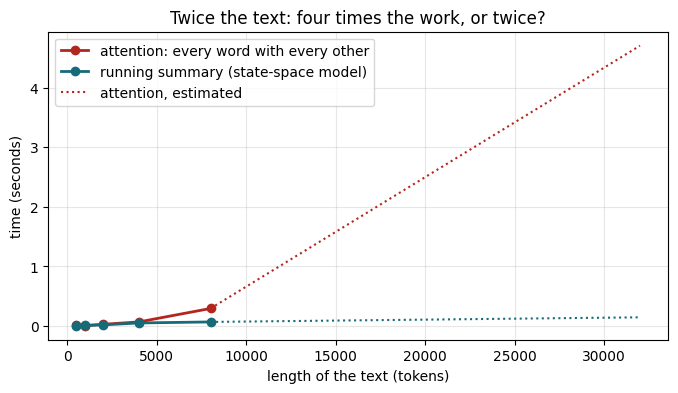

Comparisons for 1,000 tokens: attention 1,000,000, running summary 1,000
Comparisons for 32,000 tokens: attention 1,024,000,000, running summary 32,000
Memory for the comparisons at 32,000 tokens: attention about 4.1 GB, running summary 64 bytes


In [2]:
# Part A: time the two ways of reading a text, as the text gets longer. Just run it.
d = 16                                    # how many numbers describe each word (kept small here)
rng = onp.random.default_rng(0)
def attention(n):                         # every word compared with every other word: n x n comparisons
    Q = rng.standard_normal((n, d), dtype=onp.float32); K = rng.standard_normal((n, d), dtype=onp.float32)
    s = Q @ K.T; return s.max()
def running_summary(n):                   # read in order, keep a small summary: n small updates
    x = rng.standard_normal((n, d), dtype=onp.float32); h = onp.zeros(d, onp.float32); a = onp.float32(0.9)
    for i in range(n): h = a * h + x[i]
    return h.sum()
lengths = [500, 1000, 2000, 4000, 8000]
t_att, t_ssm = [], []
for n in lengths:
    t0 = time.time(); attention(n); t_att.append(time.time() - t0)
    t0 = time.time(); running_summary(n); t_ssm.append(time.time() - t0)
# 32,000 tokens: the summary reader is measured; attention would need about 4 GB, so it is estimated
t0 = time.time(); running_summary(32000); ssm_32k = time.time() - t0
att_32k = t_att[-1] * (32000 / 8000) ** 2
plt.figure(figsize=(8, 4))
plt.plot(lengths, t_att, "o-", color="#B3261E", linewidth=2, label="attention: every word with every other")
plt.plot(lengths, t_ssm, "o-", color="#176B78", linewidth=2, label="running summary (state-space model)")
plt.plot([8000, 32000], [t_att[-1], att_32k], ":", color="#B3261E", label="attention, estimated")
plt.plot([8000, 32000], [t_ssm[-1], ssm_32k], ":", color="#176B78")
plt.xlabel("length of the text (tokens)"); plt.ylabel("time (seconds)"); plt.title("Twice the text: four times the work, or twice?")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Comparisons for 1,000 tokens: attention {1000**2:,}, running summary {1000:,}")
print(f"Comparisons for 32,000 tokens: attention {32000**2:,}, running summary {32000:,}")
print(f"Memory for the comparisons at 32,000 tokens: attention about {32000**2 * 4 / 1e9:.1f} GB, running summary {d * 4} bytes")

## Part 1 · The class example: a model learns the sourdough starter
**The law:** how fast it rises = r × height × (1 − height ÷ top of jar). Same numbers as Week 7.

**The success test, decided before training:** *the height at 8 hours is within 0.1 cm of the answer sheet.*

Run the next two cells. The second one trains the model (a few seconds), then draws the **loss curve** and the **model against the answer sheet**.

In [3]:
# ---------- THE CLASS EXAMPLE: a sourdough starter ----------
r     = 0.5      # how fast it grows, per hour        (source: a baking book)
K     = 12.0     # the top of the jar, in cm          (source: I measured the jar)
H0    = 2.0      # the starting height, in cm
t_end = 16.0     # look from 0 to 16 hours

def rate(t, H):                          # how fast the height changes, at time t
    return r * H * (1 - H / K)           # <- THE LAW, as one line of code

def exact(t):                            # the exact formula: the answer sheet
    return K / (1 + (K / H0 - 1) * onp.exp(-r * t))

check_time = 8.0          # success test: the height at 8 hours ...
check_tolerance = 0.1     # ... is within 0.1 cm of the answer sheet
print("Class example loaded. Now run the next cell to train the model.")

Class example loaded. Now run the next cell to train the model.


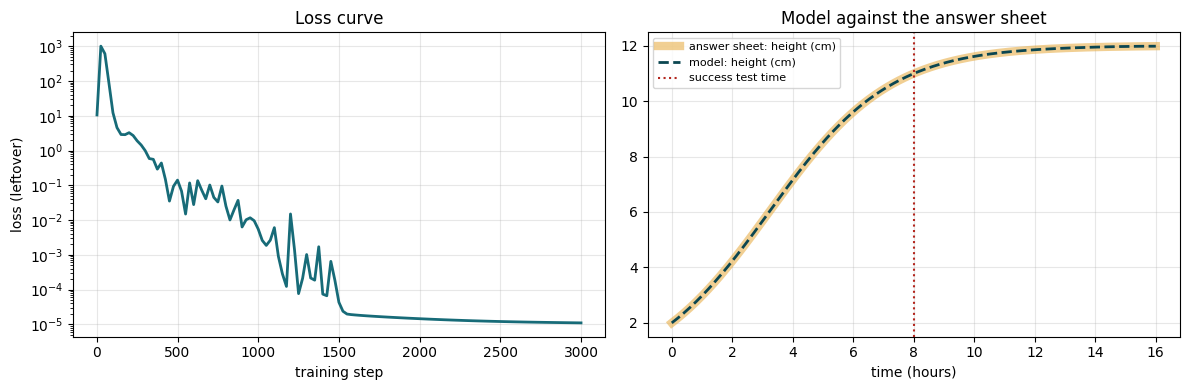

Biggest error against the answer sheet: 0.0049
Success test: at 8 hours, the model says 10.99 and the answer sheet says 10.99.
  Difference 0.000683, allowed 0.1: PASSED
Training time: 4 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as class_example_model.png.


In [4]:
# Train the model: no data, only the law. Then draw it and run the success test.
result = learn_law(rate, H0, t_end)                  # 200 checking points, 3,000 training steps
t = onp.linspace(0, t_end, 400)
class_report = report(result, t, exact(t), ["height (cm)"], "hours", check_time, check_tolerance, picture="class_example_model.png")

### Break it on purpose, then fix it
How did the model learn with no data? It checked its guess against the law at **checking points**. What if there are only **3**?

**The four fixes, in order, if your model fails:** (1) keep the numbers near 1 (choose sensible units); (2) use more checking points; (3) use a shorter time range; (4) take smaller steps (a smaller `lr`).

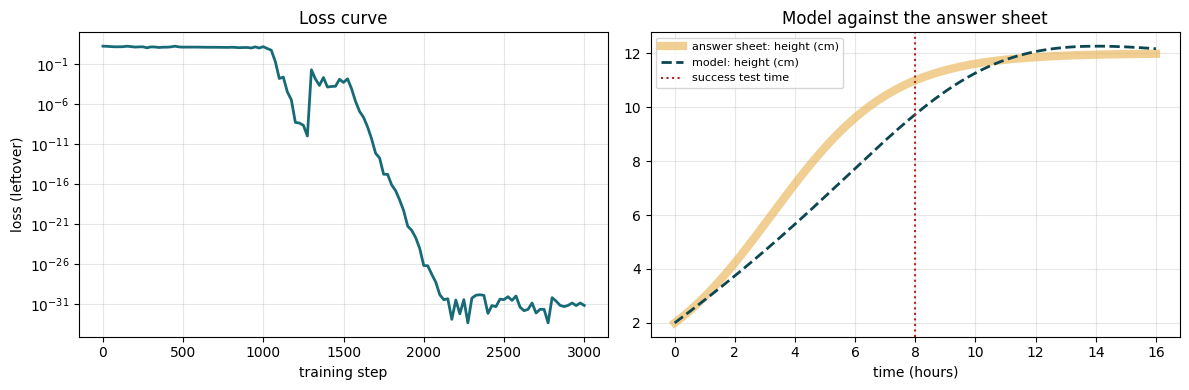

Biggest error against the answer sheet: 1.893
Success test: at 8 hours, the model says 9.734 and the answer sheet says 10.99.
  Difference 1.26, allowed 0.1: NOT YET: try the four fixes
Training time: 2 seconds. Model size: 1153 numbers. Checking points: 3.
Saved as class_example_broken.png.


In [5]:
# Broken on purpose: only 3 checking points.
broken = learn_law(rate, H0, t_end, n_points=3)
broken_report = report(broken, t, exact(t), ["height (cm)"], "hours", check_time, check_tolerance, picture="class_example_broken.png")

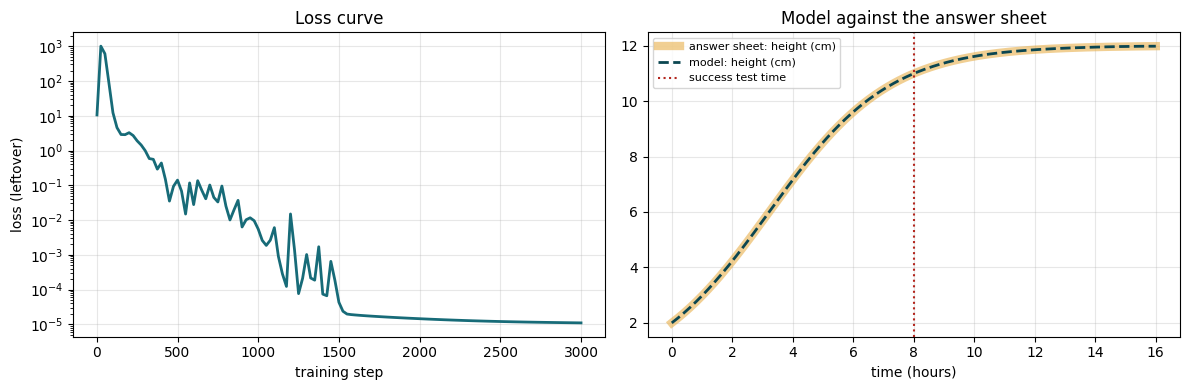

Biggest error against the answer sheet: 0.0049
Success test: at 8 hours, the model says 10.99 and the answer sheet says 10.99.
  Difference 0.000683, allowed 0.1: PASSED
Training time: 3 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as class_example_fixed.png.


In [6]:
# Fixed: back to 200 checking points (fix 2).
fixed = learn_law(rate, H0, t_end, n_points=200)
fixed_report = report(fixed, t, exact(t), ["height (cm)"], "hours", check_time, check_tolerance, picture="class_example_fixed.png")

## Part 2 · ✏️ YOUR FIRST MODEL, if one thing changes over time
1. **Copy** your Week 7 lines into the next cell: the name, the time unit, your numbers, your start, `t_end`, your law line and, if you have one, your exact formula.
2. **Set your success test** (`check_time` and `check_tolerance`), *before* you train. Use the one on your roadmap.
3. Run the cell, then the one after it.

**Tip:** if your law has a square root, write `np.sqrt(np.abs(y) + 1e-9)`, as in the placeholder below; a plain square root of a negative number stops training.

In [7]:
# ✏️ YOUR TURN. Change the lines marked <-- . Keep the notes after # up to date.
# The placeholder below is water draining from a tank through a small hole. Replace it with your law.
name      = "temperature (°C)"   # <-- what changes, with its unit
time_unit = "minutes"             # <-- your unit of time

start = 55                     # <-- the starting value
t_end = 60                     # <-- how long to look

k = 0.03                       # <-- Cooling Rate, per minute, source: Source: U. H. Kurzweg (2017),"Cooling of a Cup of Coffee", University of Florida, p. 3
T = start                      # <-- Starting coffee temperature, unit:°C, source: Average figure from https://mtpak.coffee/2022/08/takeaway-cups-coffee-temperature-ideal-serving/
Ta = 20                        # <-- Ambient room temperature, unit:°C, source: took average observed in my personal car


def my_rate(t, y):            # how fast it changes, at time t, when the value is y
    return -k * (y - Ta)      # <-- YOUR LAW: Newton’s Law of Cooling says that the hotter an object (coffee in our case) is compared with its surroundings , the faster it cools

HAS_EXACT = True              # <-- True if your law has an exact formula, otherwise False
def my_exact(t):
    return Ta + (T - Ta) * np.exp(-k * t)

check_time = 60             # <-- your success test: the time to check ...
check_tolerance = 1         # <-- ... and how close the model must be to the answer sheet there
print("Your law is loaded. Now run the next cell to train your first model.")

Your law is loaded. Now run the next cell to train your first model.


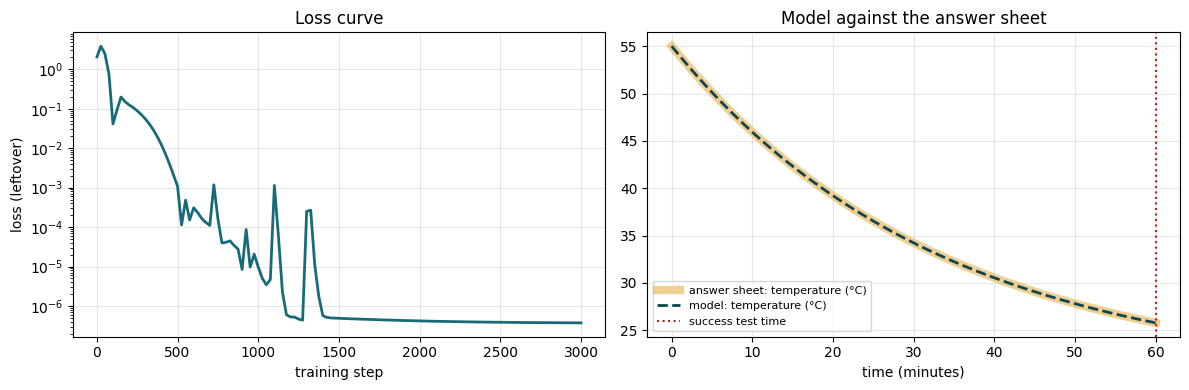

Biggest error against the answer sheet: 0.00794
Success test: at 60 minutes, the model says 25.78 and the answer sheet says 25.79.
  Difference 0.000598, allowed 1: PASSED
Training time: 4 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as my_first_model.png.
Download my_first_model.png from the folder icon on the left: you hand it in on the Week 8 form.


In [14]:
# Make the answer sheet, train your first model, and run your success test. Just run this cell.
t = onp.linspace(0, t_end, 400)
if HAS_EXACT:
    sheet = my_exact(t)
else:
    sheet = solve_ivp(lambda tt, y: [float(my_rate(tt, y[0]))], (0, t_end), [start], t_eval=t, rtol=1e-8, atol=1e-10).y[0]
my_result = learn_law(my_rate, start, t_end, lr=0.003)
my_report = report(my_result, t, sheet, [name], time_unit, check_time, check_tolerance)
print("Download my_first_model.png from the folder icon on the left: you hand it in on the Week 8 form.")

## Part 3 · ✏️ YOUR FIRST MODEL, if two or three things change each other
Copy your Week 7 Part 3 lines. The model has **one output for each thing**. Choose which thing your success test checks with `which` (0 for the first, 1 for the second, and so on).

In [ ]:
# ✏️ YOUR TURN (only if your law has two or three things that change each other).
names  = ["tank A (litres)", "tank B (litres)"]   # <-- one name per thing
k1 = 0.3                     # <-- a number    (unit, source)
k2 = 0.1                     # <-- a number    (unit, source)
starts = [10.0, 0.0]         # <-- starting values, one per thing
t_end3 = 30.0                # <-- how long to look
time_unit3 = "minutes"       # <-- your unit of time

def my_rates(t, y):
    A, B = y                 # <-- one short name per thing, in the same order as names
    dA = -k1 * A             # <-- how fast the first thing changes
    dB = k1 * A - k2 * B     # <-- how fast the second thing changes
    return [dA, dB]          # <-- list them all, in the same order

which = 1                    # <-- which thing your success test checks (0 = first, 1 = second, ...)
check_time3 = 15.0           # <-- your success test: the time to check ...
check_tolerance3 = 0.2       # <-- ... and how close it must be
print("Your law is loaded. Now run the next cell.")

In [ ]:
# Answer sheet from the solver, then train and test. Just run this cell.
t3 = onp.linspace(0, t_end3, 300)
sheet3 = solve_ivp(lambda tt, y: onp.asarray([float(v) for v in my_rates(tt, y)]), (0, t_end3), starts, t_eval=t3, rtol=1e-8, atol=1e-10).y
my_result3 = learn_law(my_rates, starts, t_end3)
my_report3 = report(my_result3, t3, sheet3, names, time_unit3, check_time3, check_tolerance3, which=which)

## Part 4 · ✏️ YOUR FIRST MODEL, if it changes over time and along a line
In Week 7 you wrote your law with `bend` (how curved the line is). Here it is called `u_xx`; `u_x` is how steep it is. The two ends stay fixed at their starting values, as in Week 7. Training takes about a minute.

In [ ]:
# ✏️ YOUR TURN (only if your law changes over time and along a line).
D = 1.0                      # <-- how fast it spreads   (km² per year, source: ...)
g = 1.0                      # <-- how fast it grows     (per year, source: ...)
L = 40.0                     # <-- length of the line    (km)
t_end4 = 8.0                 # <-- how long to look      (years)
name4 = "share of the coastline settled"   # <-- what changes

def my_line_law(u, u_x, u_xx):              # how fast it changes at a point on the line
    return D * u_xx + g * u * (1 - u)       # <-- YOUR LAW (Week 7's "bend" is u_xx here)

def u0(x):                                  # <-- the starting values along the line
    return np.exp(-x**2 / 4)

times = [0, 2, 4, 6, 8]      # <-- moments to draw (the last one is t_end4)
check_place, check_time4, check_tolerance4 = 10.0, 8.0, 0.05   # <-- your success test
print("Your law is loaded. Now run the next cell (about a minute).")

In [ ]:
# Answer sheet from the solver, then train and test. Just run this cell.
x4, sheet4 = line_answer_sheet(my_line_law, lambda xx: onp.asarray(u0(xx)), L, t_end4, times)
my_result4 = learn_line_law(my_line_law, u0, L, t_end4)
my_report4 = line_report(my_result4, x4, sheet4, times, name4, check_place, check_time4, check_tolerance4)

## Done · What to hand in (the Week 8 form)
- **Your error** against the answer sheet, and **your success test**: passed or not yet.
- **Training time** and **model size** (both are printed above).
- **The picture** `my_first_model.png` (folder icon on the left → ⋮ → Download).
- **One problem you fixed**, and how.
- **Applied checkpoint:** two or three sentences on **where your model could go wrong**: what your law leaves out, the numbers you chose, and Week 5's wrong-law lesson.

**When it goes wrong**
- *The loss stays high:* it has not found the law yet. Try the four fixes in order.
- *The loss jumps up and down:* the steps are too big. Add `lr=0.003` inside `learn_law( ... )`.
- *The loss is tiny but the model is wrong:* too few checking points (remember Part 1).
- *The loss says `nan`:* a square root or logarithm of a negative number. See the tip in Part 2.
- *"Training got stuck... starting again":* this is normal; the tools try a fresh start, up to three times.